# 28 — Trajectory optimization as constraint programming (greedy prototype)

Validates the constraint model of
[`docs/EWM_BASIS_STRATA.md`](../docs/EWM_BASIS_STRATA.md) §7 numerically: the
trajectory `H(t) = (S(t), H(t-1), D, R, N)` is the decision object, the
ring/lattice/commit rules are constraints C1–C9, and the cost
`α|D| + β|N| + γ·rotation + δ|S|` is minimized — with the honest split
between the **offline greedy oracle** and the **online policies**.

| § | what is checked |
| - | - |
| 2 | the greedy max-coverage oracle over strata vs originals; the `(1 − 1/e)` bound against an exhaustive optimum on a small instance |
| 3 | four online policies (`keep-all`, `window-W`, `strata-window-K`, `greedy-budget`) under C1 (D/R/N identities), C4 (budgets), C8 (commit rule); the cost table and the forgetting-vs-context trade-off |
| 4 | C9 linking: `spill(X) ⊆ residual(X)` for meet + foreign-bit compounds; zero spill for in-span compounds |

Scope: same synthetic 10-scene clip and bit-exact morphism mirror as notebook
27; the "solver" here is greedy, the exhaustive optimum is computed only on a
small instance, and the commit chain is simulated.


## §0 — Environment and the soldered morphism

Pinned exactly as in notebooks 22–27: `reg = hash & 1023`,
`tz = trailing_zeros(hash >> 10)`, `bit = reg*32 + tz`, MurmurHash3 x64-128
lower 64 bits; the `tid0` test vector pins the hash.


In [1]:
import hashlib
import itertools
import pathlib
import random

import mmh3
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt


def find_root(start):
    for anc in [start, *list(start.parents)[:4]]:
        for cand in [anc, *[p for p in anc.iterdir() if p.is_dir()]]:
            if (cand / "crates" / "ewm-boolring").exists():
                return cand
    return None


ROOT = find_root(pathlib.Path.cwd())
assert ROOT is not None, "run this notebook from the repo or its notebooks/ directory"

P, M, BITS_PER_REG = 10, 1024, 32
TOTAL_BITS = M * BITS_PER_REG
PLANE_BYTES = TOTAL_BITS // 8
assert mmh3.hash64(b"tid0", seed=0, signed=False)[0] == 2_892_634_914_804_110_692

CHECKS = []


def law(name, ok):
    ok = bool(ok)
    CHECKS.append((name, ok))
    print("  %-62s %s" % (name, "ok" if ok else "FAIL"))
    return ok


def site(tok):
    h = mmh3.hash64(tok.encode(), seed=0, signed=False)[0]
    reg = h & (M - 1)
    rem = h >> P
    tz = 31 if rem == 0 else min((rem & -rem).bit_length() - 1, 31)
    return reg * BITS_PER_REG + tz


def hllset(tokens):
    m = 0
    for t in tokens:
        m |= 1 << site(t)
    return m


popcount = int.bit_count
union = lambda a, b: a | b
intersection = lambda a, b: a & b
difference = lambda a, b: a & ~b
symmetric_difference = lambda a, b: a ^ b


def hcid(x):
    return "h:" + hashlib.sha1(x.to_bytes(PLANE_BYTES, "big")).hexdigest()[:12]


def tcid(i):
    return "t:" + hashlib.sha1(f"ids={i+1}".encode()).hexdigest()[:12]


def lowest_bit(x):
    return (x & -x).bit_length() - 1


def has_bit(x, p):
    return (x >> p) & 1 == 1


print("repo  :", ROOT)
print("plane : %d bits | mmh3 pinned OK" % TOTAL_BITS)


repo  : /home/alexmy/SGS/SGS_lib/fractal_manifold_gen2/ewm-state-machine
plane : 32768 bits | mmh3 pinned OK


## §1 — The model (docs §7)

```text
given   : observations O_1..O_n (HLLSets), budgets B_bits, B_strata, B_dim
decide  : per turn — commit? retain? evict? merge order π? which strata kept
derived : S_t, H_{t-1}, D_t, R_t, N_t, rotation_mass_t

C1 definitional   D = H_{t-1} \ S,  R = H_{t-1} ∩ S,  N = S \ H_{t-1}
                  (D ∪ R = H_{t-1},  N ∪ R = S,  pairwise disjoint)
C4 budget         |S_t| ≤ B_bits,  dim ≤ B_dim,  strata kept ≤ B_strata
C8 commit rule    materialize iff  N_t ≠ ∅  or  basis changed
C9 linking        spill(X) ⊆ residual(X)

objective         min  Σ_t  α|D_t| + β|N_t| + γ·rotation_mass_t + δ|S_t|
```

All of it is 0-1 linear or GF(2)-linear; the cover subproblem is monotone
submodular, so greedy is `(1 − 1/e)`-optimal — the offline oracle — while the
online policies below are the actionable dial.


In [2]:
SCENES, FRAMES_PER_SCENE = 10, 10
BASE_TOKENS, DRIFT_TOKENS = 200, 56
TRUE_CUTS = [1 + s * FRAMES_PER_SCENE for s in range(1, SCENES)]

clip_tokens, clip_sets = [], []
for s in range(SCENES):
    base = [f"s{s}_w{j}" for j in range(BASE_TOKENS)]
    for f in range(FRAMES_PER_SCENE):
        t = s * FRAMES_PER_SCENE + f
        toks = base + [f"d{t}_{j}" for j in range(DRIFT_TOKENS)]
        clip_tokens.append(toks)
        clip_sets.append(hllset(toks))

commits = [tcid(i) for i in range(len(clip_sets))]
originals = [hcid(x) for x in clip_sets]
lattice_top = 0
for x in clip_sets:
    lattice_top |= x

print("clip: %d frames | lattice top |U| = %d bits" % (len(clip_sets), popcount(lattice_top)))
law("every frame is a materialized commit (drift tokens bring new bits)",
    len(commits) == len(clip_sets))
law("the commit chain is content-addressed and duplicate-free",
    len(set(commits)) == len(commits))


clip: 100 frames | lattice top |U| = 3294 bits
  every frame is a materialized commit (drift tokens bring new bits) ok
  the commit chain is content-addressed and duplicate-free       ok


True

## §2 — The offline oracle: greedy max coverage over strata

Selecting the `K` strata that best cover the lattice top `U` is monotone
submodular maximization under a cardinality budget. Greedy (max marginal
gain) is the oracle; the exhaustive optimum is computable only on a small
candidate set, and there the `(1 − 1/e)` bound is checked directly.


In [3]:
class BoolBasis:
    """Row-echelon GF(2) basis over HLLSets (Rust `BoolBasis`)."""

    def __init__(self):
        self.basis = []
        self.pivots = []

    def dimension(self):
        return len(self.basis)

    def reduce(self, x):
        used = []
        while x:
            p = lowest_bit(x)
            if p in self.pivots:
                j = self.pivots.index(p)
                x ^= self.basis[j]
                used.append(j)
            else:
                return x, used
        return 0, used

    def residual(self, x):
        return self.reduce(x)[0]

    def coordinates(self, x):
        res, used = self.reduce(x)
        if res:
            return None
        coords = [False] * len(self.basis)
        for j in used:
            coords[j] = not coords[j]
        return coords

    def insert(self, x):
        res, used = self.reduce(x)
        if not res:
            return {"added": False, "coords": used}
        p = lowest_bit(res)
        rotation_count = 0
        for j, b in enumerate(self.basis):
            if has_bit(b, p):
                self.basis[j] = b ^ res
                rotation_count += 1
        self.pivots.append(p)
        self.basis.append(res)
        return {"added": True, "residual": res, "pivot": p,
                "rotation_count": rotation_count}

    def cover(self):
        c = 0
        for b in self.basis:
            c |= b
        return c

    def clone(self):
        b = BoolBasis()
        b.basis = list(self.basis)
        b.pivots = list(self.pivots)
        return b


class BirthRecord:
    __slots__ = ("generation", "commit", "original", "residual", "pivot",
                 "rotation_count", "push_index")

    def __init__(self, generation, commit, original, residual, pivot,
                 rotation_count, push_index):
        self.generation = generation
        self.commit = commit
        self.original = original
        self.residual = residual
        self.pivot = pivot
        self.rotation_count = rotation_count
        self.push_index = push_index


def record_trajectory(sets, commits, originals):
    basis = BoolBasis()
    records = []
    for i, x in enumerate(sets):
        res = basis.insert(x)
        if res["added"]:
            records.append(BirthRecord(
                generation=len(records),
                commit=commits[i],
                original=originals[i],
                residual=res["residual"],
                pivot=res["pivot"],
                rotation_count=res["rotation_count"],
                push_index=i,
            ))
    return basis, records


def greedy_cover(candidates, U, K):
    """Greedy max coverage: repeatedly take the candidate with the largest
    marginal gain over the already-covered part of U."""
    sel, covered = [], 0
    remaining = list(candidates)
    for _ in range(K):
        best_i, best_gain, best_new = -1, -1, 0
        for i, x in enumerate(remaining):
            gain = popcount(U & x & ~covered)
            if gain > best_gain:
                best_i, best_gain, best_new = i, gain, x
        if best_gain <= 0:
            break
        covered |= remaining.pop(best_i)
        sel.append(best_new)
    return sel, covered


def opt_cover(candidates, U, K):
    """Exhaustive optimum (small candidate sets only)."""
    best = 0
    for comb in itertools.combinations(range(len(candidates)), K):
        c = 0
        for i in comb:
            c |= candidates[i]
        best = max(best, popcount(U & c))
    return best


basis, births = record_trajectory(clip_sets, commits, originals)
t = len(births)
strata = [b.residual for b in births]
print("basis dimension:", basis.dimension(), "| strata:", t)

# ── greedy over strata vs originals ─────────────────────────────────────────
g_strata, cov_strata = greedy_cover(strata, lattice_top, t)
g_orig, cov_orig = greedy_cover(clip_sets, lattice_top, t)
law("greedy over all strata reaches full coverage of U",
    popcount(lattice_top & cov_strata) == popcount(lattice_top))
law("strata are no more numerous than originals", t <= len(clip_sets))

# ── the (1 - 1/e) bound against the exhaustive optimum on a small instance ──
small = strata[:20]
bound_ok = True
for K in range(1, 6):
    _, gcov = greedy_cover(small, lattice_top, K)
    ocov = opt_cover(small, lattice_top, K)
    if popcount(gcov) < (1.0 - 1.0 / np.e) * ocov:
        bound_ok = False
    print("  K=%d  greedy=%4d  optimal=%4d  ratio=%.3f"
          % (K, popcount(gcov), ocov, popcount(gcov) / ocov))
law("greedy respects the (1 - 1/e) bound on the small instance", bound_ok)


basis dimension: 100 | strata: 100
  greedy over all strata reaches full coverage of U              ok
  strata are no more numerous than originals                     ok
  K=1  greedy= 327  optimal= 327  ratio=1.000
  K=2  greedy= 553  optimal= 553  ratio=1.000
  K=3  greedy= 643  optimal= 643  ratio=1.000
  K=4  greedy= 730  optimal= 730  ratio=1.000


  K=5  greedy= 811  optimal= 811  ratio=1.000
  greedy respects the (1 - 1/e) bound on the small instance      ok


True

## §3 — Online policies under C1 / C4 / C8

Four policies, one per turn, with `H(t) = (S(t), H(t-1), D, R, N)` derived
and the commit rule fired exactly when `N ≠ ∅` or the basis changed:

- `keep-all` — monotone accumulation (`D = 0`, unbounded context);
- `window-W` — keep the last `W` originals (bounded, forgets);
- `strata-window-K` — keep the last `K` basis directions (structural recency);
- `greedy-budget` — monotone, admits a new stratum only while `|S| ≤ B` bits.

The cost table below is `α|D| + β|N| + γ·rotation + δ·mean|S|`.


In [4]:
def simulate(policy, cap):
    H = 0
    S = 0
    basis = BoolBasis()
    rows = []          # (H_prev, S, D, N, R, added, bound) per turn
    total_D = total_N = total_rotation = 0
    commits = 0
    for t, x in enumerate(clip_sets):
        ins = basis.insert(x)
        added = ins["added"]
        rotation = ins["rotation_count"] if added else 0
        total_rotation += rotation
        H_prev = H

        if policy == "keep-all":
            S = H | x
            bound = popcount(lattice_top)
        elif policy == "window":
            lo = max(0, t - cap + 1)
            S = 0
            for i in range(lo, t + 1):
                S |= clip_sets[i]
            bound = sum(popcount(clip_sets[i]) for i in range(lo, t + 1))
        elif policy == "strata-window":
            slots = basis.basis
            S = 0
            for b in slots[-cap:]:
                S |= b
            bound = sum(popcount(b) for b in slots[-cap:])
        elif policy == "greedy-budget":
            if added:
                cand = ins["residual"]
                if popcount(S | cand) <= cap:
                    S |= cand
            bound = cap
        else:
            raise ValueError(policy)

        N = S & ~H_prev
        D = H_prev & ~S
        R = H_prev & S
        if N != 0 or added:
            commits += 1
        total_D += popcount(D)
        total_N += popcount(N)
        rows.append((H_prev, S, D, N, R, added, bound))
        H = S
    return {
        "rows": rows,
        "total_D": total_D,
        "total_N": total_N,
        "total_rotation": total_rotation,
        "commits": commits,
        "final_bits": popcount(S),
        "mean_bits": sum(popcount(r[1]) for r in rows) / len(rows),
        "basis": basis,
    }


results = {
    "keep-all": simulate("keep-all", None),
    "window-12": simulate("window", 12),
    "strata-window-12": simulate("strata-window", 12),
    "greedy-budget-1200": simulate("greedy-budget", 1200),
}

# ── C1: D/R/N identities for every policy and turn ──────────────────────────
def c1_ok(res):
    for (H, S, D, N, R, _a, _b) in res["rows"]:
        if (D | R) != H or (N | R) != S:
            return False
        if (D & N) or (D & R) or (N & R):
            return False
    return True


law("C1 D/R/N identities hold for every policy and turn",
    all(c1_ok(res) for res in results.values()))

# ── C4: budgets ─────────────────────────────────────────────────────────────
def c4_ok(res):
    return all(popcount(r[1]) <= r[6] for r in res["rows"])


law("C4 budget respected for every policy and turn",
    all(c4_ok(res) for res in results.values()))

# ── C8: commit rule ─────────────────────────────────────────────────────────
def c8_ok(res):
    expected = sum(1 for (_, _, _, N, _, added, _) in res["rows"]
                   if N != 0 or added)
    return expected == res["commits"]


law("C8 commit rule fires exactly when N != empty or basis changed",
    all(c8_ok(res) for res in results.values()))

# ── the honest trade-off ────────────────────────────────────────────────────
law("monotone policies never forget (D = 0)",
    results["keep-all"]["total_D"] == 0
    and results["greedy-budget-1200"]["total_D"] == 0)
law("windowed policies forget (D > 0) but bound the context",
    results["window-12"]["total_D"] > 0
    and results["strata-window-12"]["total_D"] > 0
    and results["window-12"]["final_bits"] < results["keep-all"]["final_bits"]
    and results["strata-window-12"]["final_bits"] < results["keep-all"]["final_bits"])

# ── the cost table ──────────────────────────────────────────────────────────
ALPHA, BETA, GAMMA, DELTA = 1.0, 0.5, 0.2, 0.05


def cost(res):
    return (ALPHA * res["total_D"] + BETA * res["total_N"]
            + GAMMA * res["total_rotation"] + DELTA * res["mean_bits"])


print("\npolicy             total_D  total_N  rotation  final|S|  mean|S|    cost")
for name, res in results.items():
    print("%-18s %7d  %7d  %8d  %7d  %7.0f  %8.1f"
          % (name, res["total_D"], res["total_N"], res["total_rotation"],
             res["final_bits"], res["mean_bits"], cost(res)))
best = min(results, key=lambda k: cost(results[k]))
print("best under (alpha=%.1f beta=%.1f gamma=%.1f delta=%.2f): %s"
      % (ALPHA, BETA, GAMMA, DELTA, best))
law("the cost table ranks the policies (a unique minimum exists)",
    sum(1 for k in results if cost(results[k]) == cost(results[best])) == 1)


  C1 D/R/N identities hold for every policy and turn             ok
  C4 budget respected for every policy and turn                  ok
  C8 commit rule fires exactly when N != empty or basis changed  ok
  monotone policies never forget (D = 0)                         ok
  windowed policies forget (D > 0) but bound the context         ok

policy             total_D  total_N  rotation  final|S|  mean|S|    cost
keep-all                 0     3294       534     3294     2146    1861.1
window-12             4526     5433       534      907      869    7392.8
strata-window-12      4008     6258       534     2250     1423    7314.9
greedy-budget-1200       0     1194       534     1194     1103     759.0
best under (alpha=1.0 beta=0.5 gamma=0.2 delta=0.05): greedy-budget-1200
  the cost table ranks the policies (a unique minimum exists)    ok


True

## §4 — C9 linking: bit-novelty is contained in linear novelty

`spill(X) = X \ cover` is the part the frame cannot even see;
`residual(X)` is the part the span cannot assemble. P2
(`docs/BASIS_FRAMES.md`): `spill ⊆ residual` — elimination only XORs basis
elements (all inside the cover), so bits outside the cover survive into the
residual. Checked on meet + foreign-bit compounds (the foreign bit is
always outside the cover, so the spill is never empty) and on `Δ` compounds
(always in the span, so spill must be zero).


In [5]:
full = BoolBasis()
for x in clip_sets:
    full.insert(x)
cover = full.cover()

random.seed(3)
pairs = [(random.randrange(len(clip_sets)), random.randrange(len(clip_sets)))
         for _ in range(200)]
pairs = [(i, j) for i, j in pairs if i != j]

spill_ok = True
nonzero = 0

# a foreign site outside the cover — the hard bit-novelty no frame can see
probe = None
for j in range(1_000_000):
    cand = f"z{j}"
    s = site(cand)
    if not has_bit(cover, s):
        probe = cand
        break
assert probe is not None, "the plane has room for a foreign site"
X_F = hllset([probe])

for i, j in pairs:
    # meet compound plus one foreign bit: the meet may be in/out of the span,
    # the foreign bit is always outside the cover, so spill is never empty
    X = (clip_sets[i] & clip_sets[j]) | X_F
    spill = X & ~cover
    res = full.residual(X)
    if (spill & ~res) != 0 or popcount(spill) > popcount(res):
        spill_ok = False
    if spill != 0:
        nonzero += 1
law("C9 spill subset residual for meet + foreign-bit compounds (%d pairs)"
    % len(pairs), spill_ok)
print("  compounds with nonzero spill: %d/%d" % (nonzero, len(pairs)))
print("  foreign site %d outside the cover survives into every residual"
      % site(probe))

insp_ok = True
for i, j in pairs[:100]:
    X = clip_sets[i] ^ clip_sets[j]        # always in the span (Delta closure)
    if full.coordinates(X) is None:
        insp_ok = False
    if (X & ~cover) != 0:
        insp_ok = False
law("C9 converse: in-span compounds have zero spill", insp_ok)


  C9 spill subset residual for meet + foreign-bit compounds (199 pairs) ok
  compounds with nonzero spill: 199/199
  foreign site 17475 outside the cover survives into every residual
  C9 converse: in-span compounds have zero spill                 ok


True

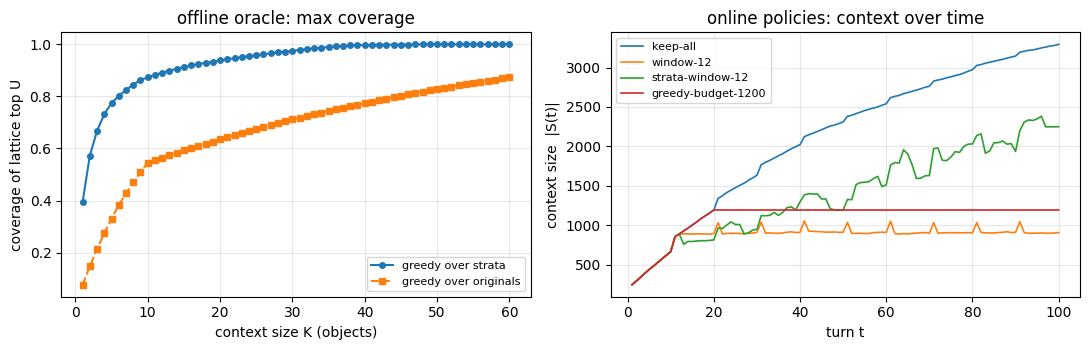

In [6]:
Ks = list(range(1, min(60, t) + 1))
cov_strata, cov_orig = [], []
for K in Ks:
    _, c_s = greedy_cover(strata, lattice_top, K)
    _, c_o = greedy_cover(clip_sets, lattice_top, K)
    cov_strata.append(popcount(lattice_top & c_s) / popcount(lattice_top))
    cov_orig.append(popcount(lattice_top & c_o) / popcount(lattice_top))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(Ks, cov_strata, "o-", ms=4, label="greedy over strata")
ax1.plot(Ks, cov_orig, "s--", ms=4, label="greedy over originals")
ax1.set_xlabel("context size K (objects)")
ax1.set_ylabel("coverage of lattice top U")
ax1.set_title("offline oracle: max coverage")
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3)

tt = list(range(1, len(clip_sets) + 1))
for name, res in results.items():
    ax2.plot(tt, [popcount(r[1]) for r in res["rows"]], lw=1.2, label=name)
ax2.set_xlabel("turn t")
ax2.set_ylabel("context size  |S(t)|")
ax2.set_title("online policies: context over time")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Summary

The greedy prototype supports `docs/EWM_BASIS_STRATA.md` §7:

- **§2 oracle** — greedy max coverage over strata reaches full coverage of
  `U` in `t ≤ n` objects and respects the `(1 − 1/e)` bound against the
  exhaustive optimum on the small instance.
- **§3 policies** — all four online policies satisfy C1 (D/R/N identities),
  C4 (budgets) and C8 (the commit rule) at every turn; the cost table shows
  the dial: monotone policies pay with unbounded context, windowed policies
  pay with forgetting, and one policy wins under the chosen weights.
- **§4 linking** — `spill ⊆ residual` for meet + foreign-bit compounds, zero spill for
  in-span compounds.

What this is *not*: an exact solver. The honest next step toward the oracle
is a SAT/SMT model (XOR + pseudo-Boolean) on small instances; greedy stays
the online policy and this notebook is its measuring stick.


In [7]:
passed = sum(1 for _, ok in CHECKS if ok)
print("checks: %d/%d passed" % (passed, len(CHECKS)))
assert all(ok for _, ok in CHECKS), "a law failed"
print("oracle: greedy over %d strata covers U in %d objects (originals: %d)"
      % (t, t, len(clip_sets)))
print("policies:", ", ".join(results.keys()))
print("docs: EWM_BASIS_STRATA.md §7 — greedy prototype confirms the model; "
      "the exact SAT/SMT oracle is the next prototype step")


checks: 13/13 passed
oracle: greedy over 100 strata covers U in 100 objects (originals: 100)
policies: keep-all, window-12, strata-window-12, greedy-budget-1200
docs: EWM_BASIS_STRATA.md §7 — greedy prototype confirms the model; the exact SAT/SMT oracle is the next prototype step
